## 1 setup

In [1]:
%pip install -q "datasets==3.6.0" pandas pyarrow numpy scipy scikit-learn tqdm matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import ast
import json
import math
import re #espressioni regolari
from pathlib import Path

import joblib #salvare oggetti python
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix,save_npz,load_npz 
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer #trasforma testi dei prodotti in vettori numerici
from sklearn.preprocessing import normalize 
from tqdm.auto import tqdm

pd.set_option("display.max_columns",100)
pd.set_option("display.max_colwidth",160)
pd.set_option("display.float_format",lambda x:f"{x:,.6f}")

c:\Users\arsid\Desktop\Tesi-ecommerce\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
CATEGORY="AmazonLike_v1"
DATASET_NAME="test_dataset2"
RANDOM_STATE=42
K_VALUES=(5,10,20)
PRIMARY_METRIC="ndcg"
PRIMARY_K=10

MAX_EVAL_ROWS=None
SAVE_RANKS=True
SAVE_CONTENT_ARTIFACTS=True

MAX_TFIDF_FEATURES=20000 #20000 termini/caratteristiche testuali al max
TFIDF_MIN_DF=2 #tiene parole che compaiono in almeno due prodotti
TFIDF_MAX_DF=0.85 #elimina parole che compaiono nell 85% dei prodotti
TFIDF_NGRAM_RANGE=(1,2)  #usa sia parole singole, sia doppie
TFIDF_STOP_WORDS="english"  #rimuove parole comuni inglesi


RUN_HYBRID_GRID_SEARCH=True
HYBRID_GRID_STEP=0.05
HYBRID_GRID_INCLUDE_ZERO=True
HYBRID_GRID_TOP_MODELS_TO_KEEP=5
HYBRID_GRID_TOP_ROWS_TO_DISPLAY=20

HYBRID_CONFIGS={ #combinare content-based, svd e popularity
    "Hybrid_Content70_Pop30":{"content":0.70,"svd":0.00,"popularity":0.30},
    "Hybrid_SVD70_Content30":{"content":0.30,"svd":0.70,"popularity":0.00},
    "Hybrid_SVD50_Content25_Pop25":{"content":0.25,"svd":0.50,"popularity":0.25},
    "Hybrid_SVD40_Content40_Pop20":{"content":0.40,"svd":0.40,"popularity":0.20},
}

## 2 caricamento dati

In [4]:
PROJECT_ROOT=Path("..").resolve() if (Path("..")/"data").exists() else Path(".").resolve()
RECOMMENDER_DIR=PROJECT_ROOT/"data"/"processed"/f"{DATASET_NAME}_recommender"
NOTEBOOK04_DIR=RECOMMENDER_DIR/"notebook04_models"
NOTEBOOK05_DIR=RECOMMENDER_DIR/"notebook05_content_hybrid"
NOTEBOOK05_DIR.mkdir(parents=True,exist_ok=True)

TRAIN_PATH=RECOMMENDER_DIR/"train.parquet"
VALIDATION_EVAL_PATH=RECOMMENDER_DIR/"validation_eval.parquet"
TEST_EVAL_PATH=RECOMMENDER_DIR/"test_eval.parquet"
VALIDATION_NEGATIVE_PATH=RECOMMENDER_DIR/"negative_samples_validation.parquet"
TEST_NEGATIVE_PATH=RECOMMENDER_DIR/"negative_samples_test.parquet"
ITEMS_PATH=RECOMMENDER_DIR/"items.parquet"
USER_MAPPING_PATH=RECOMMENDER_DIR/"user_mapping.parquet"
ITEM_MAPPING_PATH=RECOMMENDER_DIR/"item_mapping.parquet"
SPLIT_SUMMARY_PATH=RECOMMENDER_DIR/"split_summary.json"
QA_PATH=RECOMMENDER_DIR/"qa.parquet"

NOTEBOOK04_METRICS_PATH=NOTEBOOK04_DIR/"notebook04_metrics.csv"
NOTEBOOK04_COMPARISON_PATH=NOTEBOOK04_DIR/"notebook04_comparison.csv"
NOTEBOOK04_SUMMARY_PATH=NOTEBOOK04_DIR/"notebook04_summary.json"
POPULARITY_SCORES_PATH=NOTEBOOK04_DIR/"popularity_scores.parquet"
SVD_USER_EMB_PATH=NOTEBOOK04_DIR/"best_svd_user_embeddings.npy"
SVD_ITEM_EMB_PATH=NOTEBOOK04_DIR/"best_svd_item_embeddings.npy"
SVD_INFO_PATH=NOTEBOOK04_DIR/"best_svd_info.json"


print("Project root:",PROJECT_ROOT)
print("Recommender dir:",RECOMMENDER_DIR)
print("Notebook04 dir:",NOTEBOOK04_DIR)
print("Notebook05 dir:",NOTEBOOK05_DIR)


Project root: C:\Users\arsid\Desktop\Tesi-ecommerce\notebooks\test_dataset2
Recommender dir: C:\Users\arsid\Desktop\Tesi-ecommerce\notebooks\test_dataset2\data\processed\test_dataset2_recommender
Notebook04 dir: C:\Users\arsid\Desktop\Tesi-ecommerce\notebooks\test_dataset2\data\processed\test_dataset2_recommender\notebook04_models
Notebook05 dir: C:\Users\arsid\Desktop\Tesi-ecommerce\notebooks\test_dataset2\data\processed\test_dataset2_recommender\notebook05_content_hybrid


In [5]:
#file parquet principali
train_df=pd.read_parquet(TRAIN_PATH)
validation_eval_df=pd.read_parquet(VALIDATION_EVAL_PATH)
test_eval_df=pd.read_parquet(TEST_EVAL_PATH)
validation_samples_df=pd.read_parquet(VALIDATION_NEGATIVE_PATH)
test_samples_df=pd.read_parquet(TEST_NEGATIVE_PATH)
items_df=pd.read_parquet(ITEMS_PATH)
user_mapping_df=pd.read_parquet(USER_MAPPING_PATH)
item_mapping_df=pd.read_parquet(ITEM_MAPPING_PATH)

split_summary=json.loads(SPLIT_SUMMARY_PATH.read_text(encoding="utf-8"))

notebook04_summary=json.loads(NOTEBOOK04_SUMMARY_PATH.read_text(encoding="utf-8"))


def parse_negative_items(value): #converte colonna negative_item_idxs in lista pulita di interi
    if value is None: #se mancante
        return []
    if isinstance(value,np.ndarray): #se array numpy, converte in lista
        value=value.tolist()
    if isinstance(value,(list,tuple,set)): #se lista, tupla o set, converte ogni el in intero
        return [int(item) for item in value]
    if isinstance(value,str): #se stringa, la pulisce, e la interpreta come oggetto python
        value=value.strip()
        if not value:
            return []
        parsed=ast.literal_eval(value)
        return [int(item) for item in parsed]
    try:
        if pd.isna(value):
            return []
    except (TypeError,ValueError):
        pass
    return [int(value)]

validation_samples_df=validation_samples_df.copy()
test_samples_df=test_samples_df.copy()
validation_samples_df["negative_item_idxs"]=validation_samples_df["negative_item_idxs"].apply(parse_negative_items) #applica funzione, per avere lista di interi
test_samples_df["negative_item_idxs"]=test_samples_df["negative_item_idxs"].apply(parse_negative_items)

if MAX_EVAL_ROWS is not None:
    validation_samples_df=validation_samples_df.head(int(MAX_EVAL_ROWS)).copy()
    test_samples_df=test_samples_df.head(int(MAX_EVAL_ROWS)).copy()

loaded_shapes=pd.DataFrame([ #riassunto dataframe caricati
    {"name":"train","rows":len(train_df),"cols":train_df.shape[1]},
    {"name":"validation_eval","rows":len(validation_eval_df),"cols":validation_eval_df.shape[1]},
    {"name":"test_eval","rows":len(test_eval_df),"cols":test_eval_df.shape[1]},
    {"name":"validation_samples","rows":len(validation_samples_df),"cols":validation_samples_df.shape[1]},
    {"name":"test_samples","rows":len(test_samples_df),"cols":test_samples_df.shape[1]},
    {"name":"items","rows":len(items_df),"cols":items_df.shape[1]},
    {"name":"user_mapping","rows":len(user_mapping_df),"cols":user_mapping_df.shape[1]},
    {"name":"item_mapping","rows":len(item_mapping_df),"cols":item_mapping_df.shape[1]},
])

display(loaded_shapes)
display(pd.DataFrame.from_dict(split_summary,orient="index",columns=["value"]).head(30))
display(pd.DataFrame.from_dict(notebook04_summary,orient="index",columns=["value"]).head(30))

,name,rows,cols
0,train,533383,17
1,validation_eval,229415,17
2,test_eval,229395,17
3,validation_samples,229415,8
4,test_samples,229395,8
5,items,19000,17
6,user_mapping,229426,2
7,item_mapping,19000,2


,value
category,AmazonLike_v1
dataset_name,test_dataset2
source_config,user3_item8
positive_rating_threshold,4
min_user_interactions_after,3
min_item_interactions_after,8
n_negatives,100
negative_sampling_mode,mixed_category
same_category_negative_ratio,0.500000
random_state,42


,value
category,AmazonLike_v1
dataset_name,test_dataset2
primary_metric,ndcg
primary_k,10
best_model_validation,MostPopular
best_validation_score,0.291976
models_evaluated,"[MostPopular, ItemKNN_5, ItemKNN_10, ItemKNN_50, ItemKNN_100, SVD_2, SVD_4, SVD_6, SVD_8, SVD_10, SVD_12, SVD_16, SVD_24, SVD_32]"
train_rows,533383
validation_samples,229415
test_samples,229395


## 3 costruzione del testo per ogni prodotto
metadati come nome, marca, descrizione, brand

In [6]:


if "item_idx" not in items_df.columns:
    items_df=items_df.merge(item_mapping_df,on="parent_asin",how="left")

items_df=items_df.copy()
items_df["item_idx"]=items_df["item_idx"].astype(np.int64)


def is_missing_value(value): #per vedere se un valore è mancante, None, NaN 
    if value is None:
        return True
    try:
        result=pd.isna(value)
        if isinstance(result,(bool,np.bool_)):
            return bool(result)
    except (TypeError,ValueError):
        return False
    return False


def parse_json_like(value): #converte un valore in una forma python
    if is_missing_value(value):
        return []
    if isinstance(value,(list,tuple,set,dict)):
        return value
    if isinstance(value,str): #se è stringa la pulisce dagli spazi
        text=value.strip()
        if not text or text.lower() in {"none","nan","null"}:
            return []
        try:
            return json.loads(text) #se è json valido
        except json.JSONDecodeError:
            try:
                return ast.literal_eval(text) #se quello di prima non è andato bene
            except (SyntaxError,ValueError):
                return text #se niente va, restituisce testo originale
    return value


def flatten_text(value,max_parts=40): #prende valore complesso come lista o diz e lo trasforma in una singola stringa testuale
    parsed=parse_json_like(value)
    parts=[]

    def add_part(obj): #ricorsiva
        if len(parts)>=max_parts:
            return
        if is_missing_value(obj):
            return
        if isinstance(obj,dict):  #se è dizionario, scorre chiavi e valori
            for key,val in obj.items():
                if len(parts)>=max_parts:
                    break
                if is_missing_value(val):
                    continue
                if isinstance(val,(list,tuple,set,dict)):
                    add_part(val)
                else:
                    text=str(val).strip()
                    if text:
                        parts.append(str(key)+" "+text)
        elif isinstance(obj,(list,tuple,set)): #se trova lista, tupla o set, entra dentro ogni elemento
            for item in obj:
                if len(parts)>=max_parts:
                    break
                add_part(item)
        else: #valore semplice, lo converte in testo e lo aggiunge
            text=str(obj).strip()
            if text:
                parts.append(text)

    add_part(parsed)
    return " ".join(parts) #unisce i pezzi in una stringa


def clean_text(text): #pulisce testo finale prima di darlo al TF-IDF
    text=str(text)
    text=re.sub(r"<[^>]+>"," ",text) #rimuove tag HTML
    text=re.sub(r"[^A-Za-z0-9]+"," ",text) #elimina simboli, punteggiatura, parentesi, trattini
    text=re.sub(r"\s+"," ",text) #toglie spazi multipli, e mette spazi singoli
    return text.strip().lower() 


def first_existing_value(row,columns): #prende una riga del Dataframe e una lista di colonne , poi restituisce prima valore non mancante
    for col in columns:
        if col in row.index and not is_missing_value(row[col]):
            value=str(row[col]).strip()
            if value:
                return value
    return ""

In [7]:
def build_product_text(row): #prende riga di items_df, cioè un prodotto e costruisce una stringa testuale pulita
    title=first_existing_value(row,["title"])
    category=first_existing_value(row,["source_category","category_group","category","main_category"])
    store=first_existing_value(row,["store","brand"])
    features=flatten_text(row["features_json"],max_parts=30) if "features_json" in row.index else flatten_text(row.get("features",[]),max_parts=30)
    description=flatten_text(row["description_json"],max_parts=20) if "description_json" in row.index else flatten_text(row.get("description",[]),max_parts=20)
    categories=flatten_text(row["categories_json"],max_parts=20) if "categories_json" in row.index else flatten_text(row.get("categories",[]),max_parts=20)
    details=flatten_text(row["details_json"],max_parts=12) if "details_json" in row.index else flatten_text(row.get("details",{}),max_parts=12)
    text=" ".join([title,title,category,store,features,description,categories,details]) #unisce tutto in una sola stringa
    return clean_text(text) #lo pulisce e lo ritorna

items_text_df=items_df[[col for col in items_df.columns if col in { #creiamo dataframe più piccolo
    "item_idx","parent_asin","title","source_category","category_group","category","main_category","store","brand",
    "features_json","description_json","categories_json","details_json",
    "features","description","categories","details","avg_rating","average_rating",
    "num_ratings","rating_number","price","image_url"
}]].copy()

items_text_df["content_text"]=items_text_df.apply(build_product_text,axis=1)  #applica la funzione di sopra, a ogni prodotto
items_text_df=items_text_df.sort_values("item_idx").drop_duplicates("item_idx").reset_index(drop=True) #rimuove duplicati

n_users=int(max(user_mapping_df["user_idx"].max(),train_df["user_idx"].max())+1) #n utenti
n_items=int(max(item_mapping_df["item_idx"].max(),train_df["item_idx"].max(),items_text_df["item_idx"].max())+1) #n items

content_texts=[""]*n_items #lista lunga quanto numero tot di prodotti
for row in items_text_df[["item_idx","content_text"]].itertuples(index=False): #per ogni prodotto,mette il testo nella pos corrispondente al suo item_idx
    content_texts[int(row.item_idx)]=row.content_text

empty_text_count=sum(1 for text in content_texts if not text) #conta testi vuoti
#calcoliamo quante parole ha il testo prodotto, calcoliamo media e percentili
text_length_stats=pd.Series([len(text.split()) for text in content_texts],name="tokens_per_item").describe(percentiles=[0.25,0.5,0.75,0.9,0.95])

print("n_users:",n_users)
print("n_items:",n_items)
print("prodotti con testo vuoto:",empty_text_count)
display(text_length_stats.to_frame())
display(items_text_df[["item_idx","parent_asin","title","content_text"]].head(5))

n_users: 229426
n_items: 19000
prodotti con testo vuoto: 0


,tokens_per_item
count,"19,000.000000"
mean,338.652474
std,246.279797
min,18.000000
25%,176.000000
50%,276.000000
75%,435.000000
90%,628.000000
95%,761.000000
max,"5,973.000000"


,item_idx,parent_asin,title,content_text
0,0,0615179088,Human Japanese,human japanese human japanese software brak software over 1800 recordings of example words and sentences by native speakers animations of every hiragana and...
1,1,0792283090,National Geographic World Wall Map - Decorator - Laminated (46 x 30.5 in) (National Geographic Reference Map),national geographic world wall map decorator laminated 46 x 30 5 in national geographic reference map national geographic world wall map decorator laminated...
2,2,0972683275,"VideoSecu 24"" Long Arm TV Wall Mount Low Profile Articulating Full Motion Swing Tilt Wall Bracket for Most 22"" to 55"" LED LCD UHD TV Monitor Flat Screen VES...",videosecu 24 long arm tv wall mount low profile articulating full motion swing tilt wall bracket for most 22 to 55 led lcd uhd tv monitor flat screen vesa 2...
3,3,1400501466,"Barnes & Noble NOOK Tablet 16gb (Color, BNTV250)",barnes noble nook tablet 16gb color bntv250 barnes noble nook tablet 16gb color bntv250 electronics barnes noble nook color tablettm nov 2011 bntv250 hd mov...
4,4,1400532655,"Barnes & Noble NOOK Color 7"" Tablet",barnes noble nook color 7 tablet barnes noble nook color 7 tablet electronics barnes noble get social surf the web play games even listen to music over 2 mi...


## 4 rappresentazione TF-IDF dei prodotti
La rappresentazione TF-IDF assegna peso maggiore ai termini utili a distinguere un prodotto dagli altri


In [8]:
tfidf_vectorizer=TfidfVectorizer( #configuriamo traformatore TF-IDF
    max_features=MAX_TFIDF_FEATURES, 
    min_df=TFIDF_MIN_DF,
    max_df=TFIDF_MAX_DF,
    ngram_range=TFIDF_NGRAM_RANGE,
    stop_words=TFIDF_STOP_WORDS,
    strip_accents="unicode",
    lowercase=True,
    dtype=np.float32,
)

#impara vocabolario dei testi dei prodotti, trasforma ogni prodotto in un vettore TF-IDF
item_tfidf_matrix=tfidf_vectorizer.fit_transform(content_texts).tocsr() 

#normalizza ogni riga della matrice, portati sulla stessa scala
item_tfidf_matrix=normalize(item_tfidf_matrix,norm="l2",axis=1,copy=False)
#salva i nomi delle parole/bigrammi usati
feature_names=np.array(tfidf_vectorizer.get_feature_names_out())

tfidf_stats={
    "items":int(item_tfidf_matrix.shape[0]),
    "features":int(item_tfidf_matrix.shape[1]), #num di termini TF-IDF usati, cioè colonne
    "non_zero_values":int(item_tfidf_matrix.nnz),
    "density_pct":float(item_tfidf_matrix.nnz/(item_tfidf_matrix.shape[0]*item_tfidf_matrix.shape[1])*100),
}

display(pd.DataFrame.from_dict(tfidf_stats,orient="index",columns=["value"]))
print("Prime feature:",feature_names[:30].tolist())

,value
items,"19,000.000000"
features,"20,000.000000"
non_zero_values,"3,329,125.000000"
density_pct,0.876086


Prime feature: ['00', '000', '000 000', '000 contrast', '000 dot', '000 dots', '000 dynamic', '000 hours', '000 hz', '000 movies', '000 pages', '000 photo', '000 photos', '000 songs', '000 systems', '00001', '001', '002', '003', '004g', '005', '006', '008g', '01', '01 batteries', '01 discontinued', '01 electronics', '01 inches', '01 ounces', '01 pounds']


In [9]:
def top_terms_for_item(item_idx,top_n=12): #prende un prodotto tramite indice e restituisce i suoi termini TF-IDF più importanti
    row=item_tfidf_matrix[int(item_idx)]
    if row.nnz==0:
        return []
    data=row.data # i pesi 
    indices=row.indices #gli indici delle feature
    order=np.argsort(-data)[:int(top_n)]
    return [(str(feature_names[indices[pos]]),float(data[pos])) for pos in order] #lista di coppie (termine, peso)

term_preview_rows=[]
for item_idx in items_text_df["item_idx"].head(5).astype(int).tolist(): #primi 5 prodotti di items
    term_preview_rows.append({
        "item_idx":int(item_idx),
        "parent_asin":items_text_df.loc[items_text_df["item_idx"]==item_idx,"parent_asin"].iloc[0],
        "title":items_text_df.loc[items_text_df["item_idx"]==item_idx,"title"].iloc[0] if "title" in items_text_df.columns else "",
        "top_terms":top_terms_for_item(item_idx,12),
    })

display(pd.DataFrame(term_preview_rows))

,item_idx,parent_asin,title,top_terms
0,0,0615179088,Human Japanese,"[(japanese, 0.6470310091972351), (human, 0.26679787039756775), (words, 0.2554846405982971), (software, 0.18312907218933105), (language, 0.17427387833595276)..."
1,1,0792283090,National Geographic World Wall Map - Decorator - Laminated (46 x 30.5 in) (National Geographic Reference Map),"[(geographic, 0.5666229724884033), (national, 0.33010217547416687), (names, 0.3186173737049103), (map, 0.2675572633743286), (maps, 0.23124608397483826), (wo..."
2,2,0972683275,"VideoSecu 24"" Long Arm TV Wall Mount Low Profile Articulating Full Motion Swing Tilt Wall Bracket for Most 22"" to 55"" LED LCD UHD TV Monitor Flat Screen VES...","[(vesa, 0.350364089012146), (tv, 0.2673388719558716), (videosecu, 0.2499261051416397), (wall, 0.19459006190299988), (tilt, 0.18408502638339996), (55, 0.1711..."
3,3,1400501466,"Barnes & Noble NOOK Tablet 16gb (Color, BNTV250)","[(nook, 0.4929056167602539), (barnes noble, 0.23504388332366943), (barnes, 0.23415790498256683), (noble, 0.22929832339286804), (noble nook, 0.17990939319133..."
4,4,1400532655,"Barnes & Noble NOOK Color 7"" Tablet","[(barnes noble, 0.32842639088630676), (barnes, 0.3271884322166443), (noble, 0.32039815187454224), (reading, 0.25350189208984375), (books, 0.251399964094162)..."


## 5 matrice utenti-prodotti e profili content-based
profilo di ogni utente creato sommando i vettori TF-IDF dei prodotti con cui ha interagito nel training

In [10]:
train_user_idx=train_df["user_idx"].astype(np.int64).to_numpy()
train_item_idx=train_df["item_idx"].astype(np.int64).to_numpy()
train_values=np.ones(len(train_df),dtype=np.float32) #1 per ogni interazione

#matrice sparsa train n_users x n_items
train_matrix=csr_matrix((train_values,(train_user_idx,train_item_idx)),shape=(n_users,n_items),dtype=np.float32)
train_matrix.sum_duplicates()
train_matrix.eliminate_zeros()

train_seen_by_user=( #per ogni utente salva insieme dei prodotti nel train
    train_df.groupby("user_idx")["item_idx"]
    .apply(lambda values:set(values.astype(int)))
    .to_dict()
)
#unisce tutte le interazioni note
all_interactions_for_seen=pd.concat([train_df,validation_eval_df,test_eval_df],ignore_index=True)
all_seen_by_user=(
    all_interactions_for_seen.groupby("user_idx")["item_idx"]
    .apply(lambda values:set(values.astype(int)))
    .to_dict()
)
#elenco prodotti che compaiono almeno una volta nel train
train_item_candidates=np.array(sorted(train_df["item_idx"].astype(int).unique()),dtype=np.int64)

matrix_stats={
    "n_users":int(n_users),
    "n_items":int(n_items),
    "train_interactions":int(train_matrix.nnz),
    "train_density_pct":float(train_matrix.nnz/(n_users*n_items)*100),
    "train_item_candidates":int(len(train_item_candidates)),
}

display(pd.DataFrame.from_dict(matrix_stats,orient="index",columns=["value"]))

,value
n_users,"229,426.000000"
n_items,"19,000.000000"
train_interactions,"533,383.000000"
train_density_pct,0.012236
train_item_candidates,"18,996.000000"


In [11]:
user_profile_matrix=(train_matrix@item_tfidf_matrix).tocsr() 
#matrice utenti x prodotti e matrice prodotti x terminiTF-IDF
#facciamo prodotto matriciale e ottieniamo utenti x termini TF-IDF

#normalizza ogni profilo utente
user_profile_matrix=normalize(user_profile_matrix,norm="l2",axis=1,copy=False)

profile_stats={
    "user_profiles_shape":str(user_profile_matrix.shape),
    "user_profile_non_zero_values":int(user_profile_matrix.nnz),
    "users_with_non_empty_profile":int(np.diff(user_profile_matrix.indptr).astype(bool).sum()),
}

display(pd.DataFrame.from_dict(profile_stats,orient="index",columns=["value"]))

,value
user_profiles_shape,"(229426, 20000)"
user_profile_non_zero_values,84205341
users_with_non_empty_profile,229426


## 6 funzioni di valutazione

In [12]:
#calcola posizione del prodotto positivo nella lista dei candidati
def rank_positive(user_idx,positive_item_idx,negative_item_idxs,score_fn): #riceve utente, prodotto pos, lista prodotti neg, funzione di scoring
    candidate_items=[int(positive_item_idx)]+[int(item) for item in negative_item_idxs] #lista candidati pos e neg
    scores=score_fn(int(user_idx),candidate_items) #score per ogni prodotto
    scores=np.asarray(scores,dtype=np.float64) #converte in array numpy di float64
    scores=np.nan_to_num(scores,nan=-np.inf,posinf=np.inf,neginf=-np.inf) #sistema valori anomali
    positive_score=float(scores[0]) #salva score del positivo
    rank=1
    for item_idx,score in zip(candidate_items[1:],scores[1:]): #scorre, escludendo positivo, e se neg ha score piu alto, positivo scende di una posizione
        if score>positive_score:
            rank+=1
        elif score==positive_score and int(item_idx)<int(positive_item_idx):
            rank+=1
    return int(rank),positive_score

In [13]:
#prende tutti i rank dei prodotti positivi e calcola le metriche per diversi valori di k
def calculate_topk_metrics(ranks,k_values): #riceve lista dei rank dei positivi e valori di k
    ranks_array=np.asarray(ranks,dtype=np.float64)
    rows=[]
    for k in k_values:
        hits=ranks_array<=int(k) #true se fra i primi k
        hitrate=float(np.mean(hits)) if len(ranks_array) else np.nan
        ndcg_values=np.where(hits,1.0/np.log2(ranks_array+1.0),0.0)
        mrr_values=np.where(hits,1.0/ranks_array,0.0)
        rows.append({
            "K":int(k),
            "hitrate":hitrate,
            "recall":hitrate,
            "ndcg":float(np.mean(ndcg_values)) if len(ranks_array) else np.nan,
            "mrr":float(np.mean(mrr_values)) if len(ranks_array) else np.nan,
            "n_examples":int(len(ranks_array)),
        })
    return pd.DataFrame(rows)

In [14]:
#funzione di valutazione
def evaluate_model(samples_df,model_name,score_fn,split_name,k_values=K_VALUES):
    #riceve tabella con pos e neg, nome modello, funzione dei punteggi, 
    ranks=[]
    rank_rows=[]
    iterator=samples_df.itertuples(index=False) #crea iteratore sulle righe di samplesdf
    for row in tqdm(iterator,total=len(samples_df),desc=f"Evaluate {model_name} {split_name}"): 
        #calcola il rank del positivo
        rank,positive_score=rank_positive(row.user_idx,row.positive_item_idx,row.negative_item_idxs,score_fn)
        positive_source_category=getattr(row,"positive_source_category",None)
        ranks.append(rank)
        rank_rows.append({
            "model":model_name,
            "split":split_name,
            "user_idx":int(row.user_idx),
            "positive_item_idx":int(row.positive_item_idx),
            "positive_rank":int(rank),
            "positive_score":float(positive_score),
            "num_negatives":int(len(row.negative_item_idxs)),
            "positive_source_category":positive_source_category,
        })
    metrics_df=calculate_topk_metrics(ranks,k_values) #calcola metriche aggregate
    metrics_df.insert(0,"split",split_name) #inserisce nella tabella
    metrics_df.insert(0,"model",model_name)
    ranks_df=pd.DataFrame(rank_rows)
    return metrics_df,ranks_df

## 7 modello content-based TF-IDF
punteggio contentbased è la similarità tra profilo testuale dell'utente e vettore testuale del prodotto candidato

In [15]:
def score_content_tfidf(user_idx,item_idxs):
    #riceve utente da valutare e lista dei prodotti candidati
    item_idxs=np.asarray(item_idxs,dtype=np.int64)
    user_vector=user_profile_matrix[int(user_idx)] #recupera profilo contentbased dell'utente
    if user_vector.nnz==0 or len(item_idxs)==0: 
        return np.zeros(len(item_idxs),dtype=np.float64)
    item_vectors=item_tfidf_matrix[item_idxs] #recupera vettori tfidf dei prodotti candidati
    scores=item_vectors.dot(user_vector.T) #calcola similarità tra ogni prodotto candidato e il profilo dell'utente, prodotto scalare
    #prodotto scalare corrisponde a similarità coseno, essendo normalizzati i vettori
    return np.asarray(scores.toarray()).ravel().astype(np.float64)


#valutazione del modelli ContentIDF
content_validation_metrics,content_validation_ranks=evaluate_model(
    validation_samples_df,
    "ContentTFIDF",
    score_content_tfidf,
    "validation",
)

display(content_validation_metrics)

Evaluate ContentTFIDF validation: 100%|██████████| 229415/229415 [00:51<00:00, 4435.91it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,ContentTFIDF,validation,5,0.176161,0.176161,0.125603,0.109008,229415
1,ContentTFIDF,validation,10,0.255642,0.255642,0.151124,0.119436,229415
2,ContentTFIDF,validation,20,0.375865,0.375865,0.181271,0.127580,229415


## 8 recupero segnali collaborativi notebook4

In [16]:

previous_metrics_df=pd.read_csv(NOTEBOOK04_METRICS_PATH)
previous_metrics_df["source"]="notebook04"

print("Metriche Notebook 04 disponibili:",not previous_metrics_df.empty)
display(previous_metrics_df.sort_values(["split","K","ndcg"],ascending=[True,True,False]).head(20))

Metriche Notebook 04 disponibili: True


,model,split,K,hitrate,recall,ndcg,mrr,n_examples,source
42,MostPopular,test,5,0.372733,0.372733,0.268508,0.234182,229395,notebook04
60,SVD_4,test,5,0.367950,0.367950,0.266802,0.233475,229395,notebook04
63,SVD_6,test,5,0.368447,0.368447,0.266469,0.232859,229395,notebook04
66,SVD_8,test,5,0.366399,0.366399,0.265157,0.231775,229395,notebook04
69,SVD_10,test,5,0.360827,0.360827,0.260467,0.227370,229395,notebook04
57,SVD_2,test,5,0.359384,0.359384,0.259261,0.226287,229395,notebook04
72,SVD_12,test,5,0.352375,0.352375,0.252368,0.219420,229395,notebook04
75,SVD_16,test,5,0.350544,0.350544,0.251584,0.218973,229395,notebook04
78,SVD_24,test,5,0.332706,0.332706,0.236207,0.204432,229395,notebook04
81,SVD_32,test,5,0.323385,0.323385,0.230094,0.199373,229395,notebook04


In [17]:

popularity_scores_df=pd.read_parquet(POPULARITY_SCORES_PATH)
popularity_scores={int(row.item_idx):float(row.popularity_score) for row in popularity_scores_df.itertuples(index=False)}


def score_popularity(user_idx,item_idxs): #non usa utente, essendo baseline non personalizzata
    return np.array([popularity_scores.get(int(item_idx),0.0) for item_idx in item_idxs],dtype=np.float64)

popularity_summary={
    "items_with_popularity":int(len(popularity_scores)),
    "max_popularity":float(max(popularity_scores.values())) if popularity_scores else 0.0,
    "mean_popularity":float(np.mean(list(popularity_scores.values()))) if popularity_scores else 0.0,
}

display(pd.DataFrame.from_dict(popularity_summary,orient="index",columns=["value"]))

,value
items_with_popularity,"18,996.000000"
max_popularity,"1,519.000000"
mean_popularity,28.078701


In [18]:

svd_user_embeddings=np.load(SVD_USER_EMB_PATH)
svd_item_embeddings=np.load(SVD_ITEM_EMB_PATH)
svd_info=json.loads(SVD_INFO_PATH.read_text(encoding="utf-8")) if SVD_INFO_PATH.exists() else {"model":"SVD_from_notebook04"}
svd_available=True


def score_svd(user_idx,item_idxs): #assegna score svd a una lista di prodotti candidati per un certo utente
    if not svd_available:
        return np.zeros(len(item_idxs),dtype=np.float64)
    user_vector=svd_user_embeddings[int(user_idx)]
    item_matrix=svd_item_embeddings[np.asarray(item_idxs,dtype=np.int64)]
    return (item_matrix@user_vector).astype(np.float64)

print("SVD disponibile:",svd_available)
display(pd.DataFrame.from_dict(svd_info,orient="index",columns=["value"]) if svd_info else pd.DataFrame())

SVD disponibile: True


,value
model,SVD_4
requested_components,4
actual_components,4
explained_variance_ratio,0.010218


## 9 modelli ibridi semplici
score finale= pesocontent * content + pesosvd * svd + pesopopolarità * popolarità

In [19]:
def minmax_normalize_scores(scores): #porta gli score nell'intervallo 0-1
    scores=np.asarray(scores,dtype=np.float64)
    if len(scores)==0:
        return scores
    scores=np.nan_to_num(scores,nan=0.0,posinf=0.0,neginf=0.0) #toglie valori problematici
    min_score=float(np.min(scores)) 
    max_score=float(np.max(scores))
    if not np.isfinite(min_score) or not np.isfinite(max_score) or max_score<=min_score: #controlla se normalizzazione è impossibile
        return np.zeros(len(scores),dtype=np.float64)
    return (scores-min_score)/(max_score-min_score) #score normalizzato = (score-minimo)/(massimo-minimo), sempre tra 0 e 1


def make_hybrid_score_fn(weights): #crea funzione di scoring ibrida a partire da un dizionario di pesi
    content_weight=float(weights.get("content",0.0)) #peso componente contentbased
    svd_weight=float(weights.get("svd",0.0)) #peso svd
    popularity_weight=float(weights.get("popularity",0.0)) #peso popolarità

    def score_hybrid(user_idx,item_idxs): #per un utente e una lista di prodotti candidati, calcola score finale
        content_scores=minmax_normalize_scores(score_content_tfidf(user_idx,item_idxs)) #calcola score del modello contentTFIDF e li normalizza
        popularity_component=minmax_normalize_scores(score_popularity(user_idx,item_idxs)) #score di popolarità e normalizza
        if svd_weight>0 and svd_available:
            svd_component=minmax_normalize_scores(score_svd(user_idx,item_idxs)) #se si usa svd, calcola score e normalizza
        else: 
            svd_component=np.zeros(len(item_idxs),dtype=np.float64)
        final_scores=( #somma con pesi
            content_weight*content_scores
            +svd_weight*svd_component
            +popularity_weight*popularity_component
        )
        return final_scores

    return score_hybrid
#diz dei modelli da valutare
notebook05_score_functions={"ContentTFIDF":score_content_tfidf}
#scorre tutte le configurazioni ibride
for model_name,weights in HYBRID_CONFIGS.items():
    if weights.get("svd",0.0)>0 and not svd_available:
        print("Salto",model_name,"perché SVD non è disponibile")
        continue
    notebook05_score_functions[model_name]=make_hybrid_score_fn(weights) #crea funzione di scoring con quei pesi e la aggiunge al dizionario dei modelli

print("Modelli Notebook 05:",list(notebook05_score_functions.keys()))

Modelli Notebook 05: ['ContentTFIDF', 'Hybrid_Content70_Pop30', 'Hybrid_SVD70_Content30', 'Hybrid_SVD50_Content25_Pop25', 'Hybrid_SVD40_Content40_Pop20']


controlliamo griglia dei pesi per combinare svd4 contentbased TFIDF e popularity

In [20]:
#funzione che crea tutte le combinazioni di pesi possibili con step discreto
def build_hybrid_weight_grid(step=0.05,include_zero=True):
    n=int(round(1.0/float(step))) #calcola quante unità tra 0 e 1
    if not np.isclose(n*float(step),1.0): #evitiamo step strani, periodici
        raise ValueError("HYBRID_GRID_STEP deve dividere 1. Esempi validi: 0.10,0.05,0.02,0.01")
    min_unit=0 if include_zero else 1 #val minimo per ogni peso
    rows=[]
    for svd_units in range(min_unit,n+1): #prova tutti i possibili pesi per SVD
        for content_units in range(min_unit,n-svd_units+1): #prova tutti possibili pesi per content-based
            popularity_units=n-svd_units-content_units #calcola peso rimanente per popularity
            if popularity_units<min_unit: #salta combinazione se sotto il minimo
                continue
            #converte unità in peso reale
            svd_weight=round(svd_units/n,6)
            content_weight=round(content_units/n,6)
            popularity_weight=round(popularity_units/n,6)
            #nome modello
            model_name=(
                f"HybridGrid_SVD4_{int(round(svd_weight*100)):03d}_"
                f"Content_{int(round(content_weight*100)):03d}_"
                f"Pop_{int(round(popularity_weight*100)):03d}"
            )
            #aggiunge riga alla lista delle combinazioni
            rows.append({
                "model":model_name,
                "svd_weight":float(svd_weight),
                "content_weight":float(content_weight),
                "popularity_weight":float(popularity_weight),
            })
    return pd.DataFrame(rows)

#funz che valuta tutte le combinazioni di pesi su validation
def evaluate_hybrid_weight_grid_fast(samples_df,weight_grid_df,split_name="validation",k_values=K_VALUES):
    if weight_grid_df.empty: 
        return pd.DataFrame()
    #prende tre colonne dei pesi e le converte in matrice numpy
    weight_matrix=weight_grid_df[["svd_weight","content_weight","popularity_weight"]].to_numpy(dtype=np.float64)
    #conta quante combinazioni esistono
    n_weights=int(len(weight_grid_df))
    n_examples=0
    #dizionari per accumulare hitrate, ndcg, mrr
    hit_sums={int(k):np.zeros(n_weights,dtype=np.float64) for k in k_values}
    ndcg_sums={int(k):np.zeros(n_weights,dtype=np.float64) for k in k_values}
    mrr_sums={int(k):np.zeros(n_weights,dtype=np.float64) for k in k_values}
    #iteratore sulle righe di samples_df
    iterator=samples_df.itertuples(index=False) #ogni riga ha userid, positiveidx e negativeidxs
    #cicla su tutti gli es di validation
    for row in tqdm(iterator,total=len(samples_df),desc=f"Evaluate hybrid grid {split_name}"):
        #lista candidati da ordinare
        candidate_items=np.asarray([int(row.positive_item_idx)]+[int(item) for item in row.negative_item_idxs],dtype=np.int64)
        #calcola punteggi contentbased e li normalizza, stessa cosa per popularity dopo,e svd
        content_component=minmax_normalize_scores(score_content_tfidf(row.user_idx,candidate_items))
        popularity_component=minmax_normalize_scores(score_popularity(row.user_idx,candidate_items))
        svd_component=minmax_normalize_scores(score_svd(row.user_idx,candidate_items))
        #matrice con tre righe, per i tre punteggi dei tre modelli
        component_matrix=np.vstack([svd_component,content_component,popularity_component])
        #prodotto matriciale tra weightmatrix (n_combinazioni x 3) e componentmatrix(3 x n_candidati) e scores diventa ncombinazioni x ncandidati
        scores=weight_matrix@component_matrix 

        positive_scores=scores[:,0]
        negative_scores=scores[:,1:]
        negative_items=candidate_items[1:]
        ranks=1+np.sum(negative_scores>positive_scores[:,None],axis=1) #calcola rank del positivo
        if len(negative_items)>0: #gestiamo pareggi, consideriamo id più piccolo
            ties=(negative_scores==positive_scores[:,None])&(negative_items[None,:]<int(row.positive_item_idx))
            ranks=ranks+np.sum(ties,axis=1) #li aggiunge al rank
        ranks=ranks.astype(np.float64)
        for k in k_values: #per ogni val di k
            k=int(k) 
            hits=ranks<=k
            hit_sums[k]+=hits.astype(np.float64)
            ndcg_sums[k]+=np.where(hits,1.0/np.log2(ranks+1.0),0.0)
            mrr_sums[k]+=np.where(hits,1.0/ranks,0.0)
        n_examples+=1
    rows=[]
    for idx,weight_row in weight_grid_df.reset_index(drop=True).iterrows(): #su ogni combinazione di pesi, indice della combinazione e riga con pesi e modelli
        for k in k_values: #metriche per ogni k
            k=int(k)
            hitrate=float(hit_sums[k][idx]/n_examples) if n_examples else np.nan
            rows.append({
                "model":str(weight_row["model"]),
                "split":split_name,
                "K":k,
                "hitrate":hitrate,
                "recall":hitrate,
                "ndcg":float(ndcg_sums[k][idx]/n_examples) if n_examples else np.nan,
                "mrr":float(mrr_sums[k][idx]/n_examples) if n_examples else np.nan,
                "n_examples":int(n_examples),
                "svd_weight":float(weight_row["svd_weight"]),
                "content_weight":float(weight_row["content_weight"]),
                "popularity_weight":float(weight_row["popularity_weight"]),
            })
    return pd.DataFrame(rows) #resituisce dataframe con tutte le metriche

#variabili
hybrid_weight_grid_df=pd.DataFrame()
hybrid_grid_validation_metrics_df=pd.DataFrame()
hybrid_grid_primary_df=pd.DataFrame() #solo ndcg@10
best_hybrid_grid_weights_df=pd.DataFrame() 
hybrid_grid_model_names=set()

if RUN_HYBRID_GRID_SEARCH:
    if not svd_available:
        raise RuntimeError("Grid search ibrida bloccata: SVD4 non disponibile. Controllare gli artefatti del Notebook 04")
    hybrid_weight_grid_df=build_hybrid_weight_grid(#chiama funzione che genera tutte le combinazioni di pesi
        step=HYBRID_GRID_STEP, #con step scelto
        include_zero=HYBRID_GRID_INCLUDE_ZERO, #se permettiamo pesi=0
    )
    print("Combinazioni di pesi valutate:",len(hybrid_weight_grid_df))
    display(hybrid_weight_grid_df.head(10))
    hybrid_grid_validation_metrics_df=evaluate_hybrid_weight_grid_fast( #le valutiamo
        validation_samples_df,
        hybrid_weight_grid_df,
        "validation",
        K_VALUES,
    )
    hybrid_grid_model_names=set(hybrid_grid_validation_metrics_df["model"].unique())#salva tutti i nomi dei modelli generati dalla griglia
    hybrid_grid_primary_df=( #costruiamo tabella per poi scegliere migliori pesi
        hybrid_grid_validation_metrics_df[hybrid_grid_validation_metrics_df["K"]==PRIMARY_K]
        .sort_values([PRIMARY_METRIC,"mrr","hitrate"],ascending=False)
        .reset_index(drop=True)
    )
    best_hybrid_grid_weights_df=hybrid_grid_primary_df.head(int(HYBRID_GRID_TOP_ROWS_TO_DISPLAY)).copy() #prende migliori da mostrare
    selected_hybrid_grid_df=hybrid_grid_primary_df.head(int(HYBRID_GRID_TOP_MODELS_TO_KEEP)).copy() #migliori da tenere
    for row in selected_hybrid_grid_df.itertuples(index=False): 
        weights={
            "svd":float(row.svd_weight),
            "content":float(row.content_weight),
            "popularity":float(row.popularity_weight),
        }
        notebook05_score_functions[str(row.model)]=make_hybrid_score_fn(weights)
    print("Migliori configurazioni ibride su validation:")
    display(best_hybrid_grid_weights_df)
    print("Modelli della griglia aggiunti per rank dettagliati e test:",selected_hybrid_grid_df["model"].tolist())
else:
    print("Grid search dei pesi ibridi disattivata")

Combinazioni di pesi valutate: 231


,model,svd_weight,content_weight,popularity_weight
0,HybridGrid_SVD4_000_Content_000_Pop_100,0.000000,0.000000,1.000000
1,HybridGrid_SVD4_000_Content_005_Pop_095,0.000000,0.050000,0.950000
2,HybridGrid_SVD4_000_Content_010_Pop_090,0.000000,0.100000,0.900000
3,HybridGrid_SVD4_000_Content_015_Pop_085,0.000000,0.150000,0.850000
4,HybridGrid_SVD4_000_Content_020_Pop_080,0.000000,0.200000,0.800000
5,HybridGrid_SVD4_000_Content_025_Pop_075,0.000000,0.250000,0.750000
6,HybridGrid_SVD4_000_Content_030_Pop_070,0.000000,0.300000,0.700000
7,HybridGrid_SVD4_000_Content_035_Pop_065,0.000000,0.350000,0.650000
8,HybridGrid_SVD4_000_Content_040_Pop_060,0.000000,0.400000,0.600000
9,HybridGrid_SVD4_000_Content_045_Pop_055,0.000000,0.450000,0.550000


Evaluate hybrid grid validation: 100%|██████████| 229415/229415 [01:37<00:00, 2363.33it/s]


Migliori configurazioni ibride su validation:


,model,split,K,hitrate,recall,ndcg,mrr,n_examples,svd_weight,content_weight,popularity_weight
0,HybridGrid_SVD4_010_Content_025_Pop_065,validation,10,0.512765,0.512765,0.311657,0.249826,229415,0.100000,0.250000,0.650000
1,HybridGrid_SVD4_005_Content_030_Pop_065,validation,10,0.508781,0.508781,0.311643,0.250950,229415,0.050000,0.300000,0.650000
2,HybridGrid_SVD4_015_Content_025_Pop_060,validation,10,0.512373,0.512373,0.311641,0.249922,229415,0.150000,0.250000,0.600000
3,HybridGrid_SVD4_010_Content_030_Pop_060,validation,10,0.508476,0.508476,0.311628,0.251021,229415,0.100000,0.300000,0.600000
4,HybridGrid_SVD4_015_Content_030_Pop_055,validation,10,0.508066,0.508066,0.311526,0.251013,229415,0.150000,0.300000,0.550000
5,HybridGrid_SVD4_005_Content_025_Pop_070,validation,10,0.512682,0.512682,0.311519,0.249666,229415,0.050000,0.250000,0.700000
6,HybridGrid_SVD4_000_Content_030_Pop_070,validation,10,0.509003,0.509003,0.311481,0.250681,229415,0.000000,0.300000,0.700000
7,HybridGrid_SVD4_020_Content_025_Pop_055,validation,10,0.511824,0.511824,0.311371,0.249731,229415,0.200000,0.250000,0.550000
8,HybridGrid_SVD4_000_Content_025_Pop_075,validation,10,0.512530,0.512530,0.311273,0.249391,229415,0.000000,0.250000,0.750000
9,HybridGrid_SVD4_020_Content_030_Pop_050,validation,10,0.507482,0.507482,0.311243,0.250827,229415,0.200000,0.300000,0.500000


Modelli della griglia aggiunti per rank dettagliati e test: ['HybridGrid_SVD4_010_Content_025_Pop_065', 'HybridGrid_SVD4_005_Content_030_Pop_065', 'HybridGrid_SVD4_015_Content_025_Pop_060', 'HybridGrid_SVD4_010_Content_030_Pop_060', 'HybridGrid_SVD4_015_Content_030_Pop_055']


In [21]:
validation_metric_frames=[content_validation_metrics]
validation_rank_frames=[content_validation_ranks]

if "hybrid_grid_validation_metrics_df" in globals() and not hybrid_grid_validation_metrics_df.empty:
    validation_metric_frames.append(hybrid_grid_validation_metrics_df)

if "hybrid_grid_model_names" in globals():
    grid_model_names=set(hybrid_grid_model_names)
else:
    grid_model_names=set()

for model_name,score_fn in notebook05_score_functions.items():
    if model_name=="ContentTFIDF":
        continue
    metrics_df,ranks_df=evaluate_model(validation_samples_df,model_name,score_fn,"validation")
    if model_name not in grid_model_names:
        validation_metric_frames.append(metrics_df)
    validation_rank_frames.append(ranks_df)
    display(metrics_df)

notebook05_validation_metrics_df=pd.concat(validation_metric_frames,ignore_index=True)
notebook05_validation_metrics_df=notebook05_validation_metrics_df.drop_duplicates(["model","split","K"],keep="first")
notebook05_validation_ranks_df=pd.concat(validation_rank_frames,ignore_index=True)
notebook05_validation_metrics_df["source"]="notebook05"

display(notebook05_validation_metrics_df.sort_values(["K","ndcg"],ascending=[True,False]))

Evaluate Hybrid_Content70_Pop30 validation: 100%|██████████| 229415/229415 [01:07<00:00, 3386.48it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,Hybrid_Content70_Pop30,validation,5,0.289323,0.289323,0.190495,0.158134,229415
1,Hybrid_Content70_Pop30,validation,10,0.418495,0.418495,0.232203,0.175309,229415
2,Hybrid_Content70_Pop30,validation,20,0.567831,0.567831,0.269869,0.185600,229415


Evaluate Hybrid_SVD70_Content30 validation: 100%|██████████| 229415/229415 [01:14<00:00, 3082.40it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,Hybrid_SVD70_Content30,validation,5,0.362923,0.362923,0.258838,0.224518,229415
1,Hybrid_SVD70_Content30,validation,10,0.484951,0.484951,0.298243,0.240749,229415
2,Hybrid_SVD70_Content30,validation,20,0.623508,0.623508,0.333208,0.250310,229415


Evaluate Hybrid_SVD50_Content25_Pop25 validation: 100%|██████████| 229415/229415 [01:13<00:00, 3118.09it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,Hybrid_SVD50_Content25_Pop25,validation,5,0.374095,0.374095,0.264850,0.228859,229415
1,Hybrid_SVD50_Content25_Pop25,validation,10,0.503232,0.503232,0.306525,0.246009,229415
2,Hybrid_SVD50_Content25_Pop25,validation,20,0.646871,0.646871,0.342799,0.255944,229415


... (9 outputs left out)

,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,HybridGrid_SVD4_010_Content_030_Pop_060,validation,5,0.379966,0.379966,0.270157,0.233957,229415
1,HybridGrid_SVD4_010_Content_030_Pop_060,validation,10,0.508476,0.508476,0.311628,0.251021,229415
2,HybridGrid_SVD4_010_Content_030_Pop_060,validation,20,0.652760,0.652760,0.348051,0.260989,229415


Evaluate HybridGrid_SVD4_015_Content_030_Pop_055 validation: 100%|██████████| 229415/229415 [01:14<00:00, 3098.98it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,HybridGrid_SVD4_015_Content_030_Pop_055,validation,5,0.379971,0.379971,0.270203,0.234017,229415
1,HybridGrid_SVD4_015_Content_030_Pop_055,validation,10,0.508066,0.508066,0.311526,0.251013,229415
2,HybridGrid_SVD4_015_Content_030_Pop_055,validation,20,0.651880,0.651880,0.347828,0.260946,229415


,model,split,K,hitrate,recall,ndcg,mrr,n_examples,svd_weight,content_weight,popularity_weight,source
147,HybridGrid_SVD4_010_Content_035_Pop_055,validation,5,0.377451,0.377451,0.270392,0.235088,229415,0.100000,0.350000,0.550000,notebook05
87,HybridGrid_SVD4_005_Content_035_Pop_060,validation,5,0.377438,0.377438,0.270314,0.234982,229415,0.050000,0.350000,0.600000,notebook05
24,HybridGrid_SVD4_000_Content_035_Pop_065,validation,5,0.377573,0.377573,0.270265,0.234870,229415,0.000000,0.350000,0.650000,notebook05
201,HybridGrid_SVD4_015_Content_030_Pop_055,validation,5,0.379971,0.379971,0.270203,0.234017,229415,0.150000,0.300000,0.550000,notebook05
204,HybridGrid_SVD4_015_Content_035_Pop_050,validation,5,0.377138,0.377138,0.270167,0.234895,229415,0.150000,0.350000,0.500000,notebook05
...,...,...,...,...,...,...,...,...,...,...,...,...
182,HybridGrid_SVD4_010_Content_090_Pop_000,validation,20,0.449910,0.449910,0.207794,0.141238,229415,0.100000,0.900000,0.000000,notebook05
62,HybridGrid_SVD4_000_Content_095_Pop_005,validation,20,0.412745,0.412745,0.193971,0.133864,229415,0.000000,0.950000,0.050000,notebook05
125,HybridGrid_SVD4_005_Content_095_Pop_000,validation,20,0.410091,0.410091,0.193041,0.133383,229415,0.050000,0.950000,0.000000,notebook05
2,ContentTFIDF,validation,20,0.375865,0.375865,0.181271,0.127580,229415,NaN,NaN,NaN,notebook05


## 10 scelta del modello su validation

In [22]:
if previous_metrics_df.empty:
    validation_metrics_all_df=notebook05_validation_metrics_df.copy()
else: #unisce in un dataframe metriche val notebook4 e notebook5
    validation_metrics_all_df=pd.concat([
        previous_metrics_df[previous_metrics_df["split"]=="validation"],
        notebook05_validation_metrics_df,
    ],ignore_index=True)

target_validation_df=( #crea tab con tutti i modelli ma solo per valore di K principale
    validation_metrics_all_df[validation_metrics_all_df["K"]==PRIMARY_K]
    .sort_values(PRIMARY_METRIC,ascending=False) #ordina per ndcg
    .reset_index(drop=True)
)

target_notebook05_validation_df=( #stessa cosa ma con modelli del notebook05
    notebook05_validation_metrics_df[notebook05_validation_metrics_df["K"]==PRIMARY_K]
    .sort_values(PRIMARY_METRIC,ascending=False)
    .reset_index(drop=True)
)

best_overall_model_name=str(target_validation_df.loc[0,"model"])
best_overall_validation_score=float(target_validation_df.loc[0,PRIMARY_METRIC])
best_notebook05_model_name=str(target_notebook05_validation_df.loc[0,"model"])
best_notebook05_validation_score=float(target_notebook05_validation_df.loc[0,PRIMARY_METRIC])

print("Best overall model:",best_overall_model_name)
print("Best overall validation score:",best_overall_validation_score)
print("Best Notebook05 model:",best_notebook05_model_name)
print("Best Notebook05 validation score:",best_notebook05_validation_score)

display(target_validation_df)
display(target_notebook05_validation_df)

Best overall model: HybridGrid_SVD4_010_Content_025_Pop_065
Best overall validation score: 0.3116572316478989
Best Notebook05 model: HybridGrid_SVD4_010_Content_025_Pop_065
Best Notebook05 validation score: 0.3116572316478989


,model,split,K,hitrate,recall,ndcg,mrr,n_examples,source,svd_weight,content_weight,popularity_weight
0,HybridGrid_SVD4_010_Content_025_Pop_065,validation,10,0.512765,0.512765,0.311657,0.249826,229415,notebook05,0.100000,0.250000,0.650000
1,HybridGrid_SVD4_005_Content_030_Pop_065,validation,10,0.508781,0.508781,0.311643,0.250950,229415,notebook05,0.050000,0.300000,0.650000
2,HybridGrid_SVD4_015_Content_025_Pop_060,validation,10,0.512373,0.512373,0.311641,0.249922,229415,notebook05,0.150000,0.250000,0.600000
3,HybridGrid_SVD4_010_Content_030_Pop_060,validation,10,0.508476,0.508476,0.311628,0.251021,229415,notebook05,0.100000,0.300000,0.600000
4,HybridGrid_SVD4_015_Content_030_Pop_055,validation,10,0.508066,0.508066,0.311526,0.251013,229415,notebook05,0.150000,0.300000,0.550000
...,...,...,...,...,...,...,...,...,...,...,...,...
245,HybridGrid_SVD4_000_Content_100_Pop_000,validation,10,0.255642,0.255642,0.151124,0.119436,229415,notebook05,0.000000,1.000000,0.000000
246,ItemKNN_100,validation,10,0.148103,0.148103,0.095527,0.079550,229415,notebook04,NaN,NaN,NaN
247,ItemKNN_50,validation,10,0.132228,0.132228,0.084458,0.070063,229415,notebook04,NaN,NaN,NaN
248,ItemKNN_10,validation,10,0.111130,0.111130,0.067197,0.054090,229415,notebook04,NaN,NaN,NaN


,model,split,K,hitrate,recall,ndcg,mrr,n_examples,svd_weight,content_weight,popularity_weight,source
0,HybridGrid_SVD4_010_Content_025_Pop_065,validation,10,0.512765,0.512765,0.311657,0.249826,229415,0.100000,0.250000,0.650000,notebook05
1,HybridGrid_SVD4_005_Content_030_Pop_065,validation,10,0.508781,0.508781,0.311643,0.250950,229415,0.050000,0.300000,0.650000,notebook05
2,HybridGrid_SVD4_015_Content_025_Pop_060,validation,10,0.512373,0.512373,0.311641,0.249922,229415,0.150000,0.250000,0.600000,notebook05
3,HybridGrid_SVD4_010_Content_030_Pop_060,validation,10,0.508476,0.508476,0.311628,0.251021,229415,0.100000,0.300000,0.600000,notebook05
4,HybridGrid_SVD4_015_Content_030_Pop_055,validation,10,0.508066,0.508066,0.311526,0.251013,229415,0.150000,0.300000,0.550000,notebook05
...,...,...,...,...,...,...,...,...,...,...,...,...
231,HybridGrid_SVD4_010_Content_090_Pop_000,validation,10,0.298176,0.298176,0.169668,0.130898,229415,0.100000,0.900000,0.000000,notebook05
232,HybridGrid_SVD4_000_Content_095_Pop_005,validation,10,0.273866,0.273866,0.159141,0.124453,229415,0.000000,0.950000,0.050000,notebook05
233,HybridGrid_SVD4_005_Content_095_Pop_000,validation,10,0.272694,0.272694,0.158576,0.124065,229415,0.050000,0.950000,0.000000,notebook05
234,ContentTFIDF,validation,10,0.255642,0.255642,0.151124,0.119436,229415,NaN,NaN,NaN,notebook05


## 11 valutazione su test

In [23]:
test_metric_frames=[] #metriche aggregate del test
test_rank_frames=[] #rank dettagliati dei prodotti positivi sul test
#scorre tutti i modello disponibili nel dizionario
for model_name,score_fn in notebook05_score_functions.items():
    #lo valuta sul test set
    metrics_df,ranks_df=evaluate_model(test_samples_df,model_name,score_fn,"test")
    test_metric_frames.append(metrics_df)
    test_rank_frames.append(ranks_df)
    display(metrics_df)

notebook05_test_metrics_df=pd.concat(test_metric_frames,ignore_index=True)
notebook05_test_ranks_df=pd.concat(test_rank_frames,ignore_index=True)
notebook05_test_metrics_df["source"]="notebook05"

notebook05_metrics_df=pd.concat([notebook05_validation_metrics_df,notebook05_test_metrics_df],ignore_index=True)

if previous_metrics_df.empty:
    all_metrics_df=notebook05_metrics_df.copy()
else:
    all_metrics_df=pd.concat([previous_metrics_df,notebook05_metrics_df],ignore_index=True)

display(all_metrics_df.sort_values(["split","K","ndcg"],ascending=[True,True,False]))

Evaluate ContentTFIDF test: 100%|██████████| 229395/229395 [00:50<00:00, 4508.84it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,ContentTFIDF,test,5,0.133346,0.133346,0.092107,0.078611,229395
1,ContentTFIDF,test,10,0.205855,0.205855,0.115320,0.088055,229395
2,ContentTFIDF,test,20,0.323756,0.323756,0.144867,0.096028,229395


Evaluate Hybrid_Content70_Pop30 test: 100%|██████████| 229395/229395 [01:03<00:00, 3606.21it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,Hybrid_Content70_Pop30,test,5,0.260067,0.260067,0.162727,0.130924,229395
1,Hybrid_Content70_Pop30,test,10,0.394058,0.394058,0.205998,0.148748,229395
2,Hybrid_Content70_Pop30,test,20,0.546660,0.546660,0.244462,0.159244,229395


Evaluate Hybrid_SVD70_Content30 test: 100%|██████████| 229395/229395 [01:10<00:00, 3247.47it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,Hybrid_SVD70_Content30,test,5,0.361804,0.361804,0.265551,0.233826,229395
1,Hybrid_SVD70_Content30,test,10,0.478637,0.478637,0.303228,0.249315,229395
2,Hybrid_SVD70_Content30,test,20,0.615367,0.615367,0.337720,0.258741,229395


... (11 outputs left out)

,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,HybridGrid_SVD4_010_Content_030_Pop_060,test,5,0.378936,0.378936,0.275151,0.240930,229395
1,HybridGrid_SVD4_010_Content_030_Pop_060,test,10,0.501096,0.501096,0.314581,0.257160,229395
2,HybridGrid_SVD4_010_Content_030_Pop_060,test,20,0.644051,0.644051,0.350655,0.267025,229395


Evaluate HybridGrid_SVD4_015_Content_030_Pop_055 test: 100%|██████████| 229395/229395 [01:07<00:00, 3415.14it/s]


,model,split,K,hitrate,recall,ndcg,mrr,n_examples
0,HybridGrid_SVD4_015_Content_030_Pop_055,test,5,0.378984,0.378984,0.275238,0.241036,229395
1,HybridGrid_SVD4_015_Content_030_Pop_055,test,10,0.500525,0.500525,0.314461,0.257176,229395
2,HybridGrid_SVD4_015_Content_030_Pop_055,test,20,0.643222,0.643222,0.350474,0.267027,229395


,model,split,K,hitrate,recall,ndcg,mrr,n_examples,source,svd_weight,content_weight,popularity_weight
813,HybridGrid_SVD4_015_Content_025_Pop_060,test,5,0.382846,0.382846,0.276569,0.241530,229395,notebook05,NaN,NaN,NaN
807,HybridGrid_SVD4_010_Content_025_Pop_065,test,5,0.383086,0.383086,0.276457,0.241304,229395,notebook05,NaN,NaN,NaN
819,HybridGrid_SVD4_015_Content_030_Pop_055,test,5,0.378984,0.378984,0.275238,0.241036,229395,notebook05,NaN,NaN,NaN
816,HybridGrid_SVD4_010_Content_030_Pop_060,test,5,0.378936,0.378936,0.275151,0.240930,229395,notebook05,NaN,NaN,NaN
810,HybridGrid_SVD4_005_Content_030_Pop_065,test,5,0.378622,0.378622,0.274834,0.240607,229395,notebook05,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
149,HybridGrid_SVD4_000_Content_100_Pop_000,validation,20,0.375865,0.375865,0.181271,0.127580,229415,notebook05,0.000000,1.000000,0.000000
14,ItemKNN_100,validation,20,0.233058,0.233058,0.116649,0.085162,229415,notebook04,NaN,NaN,NaN
11,ItemKNN_50,validation,20,0.219232,0.219232,0.106076,0.075799,229415,notebook04,NaN,NaN,NaN
8,ItemKNN_10,validation,20,0.201735,0.201735,0.089705,0.060059,229415,notebook04,NaN,NaN,NaN


In [24]:
#metriche per categoria del prodotto positivo
#utile per controllare il comportamento del content-based e degli ibridi sulle categorie diverse

def calculate_group_metrics(ranks_df,group_col="positive_source_category",k_values=K_VALUES):
    if ranks_df.empty or group_col not in ranks_df.columns:
        return pd.DataFrame()
    rows=[]
    for (model,split,group_value),group_df in ranks_df.groupby(["model","split",group_col],dropna=False):
        metrics_df=calculate_topk_metrics(group_df["positive_rank"].to_numpy(),k_values)
        metrics_df.insert(0,group_col,group_value)
        metrics_df.insert(0,"split",split)
        metrics_df.insert(0,"model",model)
        rows.append(metrics_df)
    return pd.concat(rows,ignore_index=True) if rows else pd.DataFrame()

notebook05_all_ranks_df=pd.concat([notebook05_validation_ranks_df,notebook05_test_ranks_df],ignore_index=True)
notebook05_category_metrics_df=calculate_group_metrics(notebook05_all_ranks_df)

if notebook05_category_metrics_df.empty:
    print("Metriche per categoria non disponibili")
else:
    display(notebook05_category_metrics_df.sort_values(["split","K","positive_source_category","ndcg"],ascending=[True,True,True,False]))


,model,split,positive_source_category,K,hitrate,recall,ndcg,mrr,n_examples
72,HybridGrid_SVD4_010_Content_025_Pop_065,test,Appliances,5,0.247276,0.247276,0.171617,0.146796,5140
144,HybridGrid_SVD4_015_Content_025_Pop_060,test,Appliances,5,0.245331,0.245331,0.170146,0.145506,5140
36,HybridGrid_SVD4_005_Content_030_Pop_065,test,Appliances,5,0.239494,0.239494,0.168063,0.144634,5140
108,HybridGrid_SVD4_010_Content_030_Pop_060,test,Appliances,5,0.238132,0.238132,0.166533,0.143067,5140
180,HybridGrid_SVD4_015_Content_030_Pop_055,test,Appliances,5,0.237549,0.237549,0.165439,0.141861,5140
...,...,...,...,...,...,...,...,...,...
323,Hybrid_SVD50_Content25_Pop25,validation,Video Games,20,0.753633,0.753633,0.373467,0.263895,12112
287,Hybrid_SVD40_Content40_Pop20,validation,Video Games,20,0.723250,0.723250,0.366657,0.264441,12112
359,Hybrid_SVD70_Content30,validation,Video Games,20,0.728451,0.728451,0.363783,0.258639,12112
251,Hybrid_Content70_Pop30,validation,Video Games,20,0.633999,0.633999,0.297752,0.203250,12112


In [25]:
baseline_df=( #dataframe con risultati della baseline
    all_metrics_df[all_metrics_df["model"]=="MostPopular"]
    [["split","K","hitrate","recall","ndcg","mrr"]]
    .drop_duplicates(["split","K"])
    .rename(columns={
        "hitrate":"hitrate_baseline",
        "recall":"recall_baseline",
        "ndcg":"ndcg_baseline",
        "mrr":"mrr_baseline",
    })
)
#unisce 
comparison_df=all_metrics_df.merge(baseline_df,on=["split","K"],how="left")
#scorre le 4 metriche principali
for metric in ["hitrate","recall","ndcg","mrr"]:
    comparison_df[f"{metric}_delta_vs_popularity"]=comparison_df[metric]-comparison_df[f"{metric}_baseline"]
#ordina tabella finale
comparison_sorted_df=comparison_df.sort_values(["split","K","ndcg"],ascending=[True,True,False]).reset_index(drop=True)
display(comparison_sorted_df)

,model,split,K,hitrate,recall,ndcg,mrr,n_examples,source,svd_weight,content_weight,popularity_weight,hitrate_baseline,recall_baseline,ndcg_baseline,mrr_baseline,hitrate_delta_vs_popularity,recall_delta_vs_popularity,ndcg_delta_vs_popularity,mrr_delta_vs_popularity
0,HybridGrid_SVD4_015_Content_025_Pop_060,test,5,0.382846,0.382846,0.276569,0.241530,229395,notebook05,NaN,NaN,NaN,0.372733,0.372733,0.268508,0.234182,0.010114,0.010114,0.008061,0.007349
1,HybridGrid_SVD4_010_Content_025_Pop_065,test,5,0.383086,0.383086,0.276457,0.241304,229395,notebook05,NaN,NaN,NaN,0.372733,0.372733,0.268508,0.234182,0.010353,0.010353,0.007949,0.007122
2,HybridGrid_SVD4_015_Content_030_Pop_055,test,5,0.378984,0.378984,0.275238,0.241036,229395,notebook05,NaN,NaN,NaN,0.372733,0.372733,0.268508,0.234182,0.006251,0.006251,0.006730,0.006854
3,HybridGrid_SVD4_010_Content_030_Pop_060,test,5,0.378936,0.378936,0.275151,0.240930,229395,notebook05,NaN,NaN,NaN,0.372733,0.372733,0.268508,0.234182,0.006203,0.006203,0.006643,0.006749
4,HybridGrid_SVD4_005_Content_030_Pop_065,test,5,0.378622,0.378622,0.274834,0.240607,229395,notebook05,NaN,NaN,NaN,0.372733,0.372733,0.268508,0.234182,0.005889,0.005889,0.006326,0.006426
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
817,HybridGrid_SVD4_000_Content_100_Pop_000,validation,20,0.375865,0.375865,0.181271,0.127580,229415,notebook05,0.000000,1.000000,0.000000,0.632635,0.632635,0.330571,0.245008,-0.256770,-0.256770,-0.149301,-0.117428
818,ItemKNN_100,validation,20,0.233058,0.233058,0.116649,0.085162,229415,notebook04,NaN,NaN,NaN,0.632635,0.632635,0.330571,0.245008,-0.399577,-0.399577,-0.213922,-0.159846
819,ItemKNN_50,validation,20,0.219232,0.219232,0.106076,0.075799,229415,notebook04,NaN,NaN,NaN,0.632635,0.632635,0.330571,0.245008,-0.413404,-0.413404,-0.224495,-0.169209
820,ItemKNN_10,validation,20,0.201735,0.201735,0.089705,0.060059,229415,notebook04,NaN,NaN,NaN,0.632635,0.632635,0.330571,0.245008,-0.430900,-0.430900,-0.240867,-0.184949


## 12 analisi finale

In [28]:
baseline_df=( #metriche della baseline MostPopular
    all_metrics_df[all_metrics_df["model"]=="MostPopular"]
    [["split","K","hitrate","recall","ndcg","mrr"]]
    .drop_duplicates(["split","K"]) #tiene una riga per ogni coppia split e K
    .rename(columns={
        "hitrate":"hitrate_baseline",
        "recall":"recall_baseline",
        "ndcg":"ndcg_baseline",
        "mrr":"mrr_baseline",
    })
)
#unisce metriche baseline a allmetrics
comparison_df=all_metrics_df.merge(baseline_df,on=["split","K"],how="left")
#crea nuova colonna per ogni metrica, e crea il delta, cioè metrica modello - metrica mostpopular, la differenza
for metric in ["hitrate","recall","ndcg","mrr"]:
    comparison_df[f"{metric}_delta_vs_popularity"]=comparison_df[metric]-comparison_df[f"{metric}_baseline"]
#ordiniamo per split crescente, k crescente, ndcg decrescente
comparison_sorted_df=(
    comparison_df
    .sort_values(["split","K","ndcg"],ascending=[True,True,False])
    .reset_index(drop=True)
)
#teniamo solo righe con K=10
primary_comparison_df=(
    comparison_sorted_df[comparison_sorted_df["K"]==PRIMARY_K]
    .sort_values(["split",PRIMARY_METRIC,"mrr","hitrate"],ascending=[True,False,False,False])
    .reset_index(drop=True)
) #ordina split crescente, ndcg mrr hitrate descrescenti

#solo righe del test
primary_test_comparison_df=(
    primary_comparison_df[primary_comparison_df["split"]=="test"]
    .sort_values([PRIMARY_METRIC,"mrr","hitrate"],ascending=[False,False,False])
    .reset_index(drop=True)
)
#prendiamo solo righe del best overall model
selected_model_primary_df=(
    primary_comparison_df[primary_comparison_df["model"]==best_overall_model_name]
    .copy()
)

split_order={"validation":0,"test":1}
selected_model_primary_df["split_order"]=selected_model_primary_df["split"].map(split_order).fillna(99)
selected_model_primary_df=(
    selected_model_primary_df
    .sort_values("split_order") #ordiniamo la tabella per split order, val=0 e test=1
    .drop(columns="split_order")
    .reset_index(drop=True)
)

final_model_for_prototype=best_overall_model_name
fallback_model_for_prototype="MostPopular"
similar_items_model_for_prototype="ContentTFIDF"
#dizionari
selected_model_test_summary={}
selected_model_test_delta={}
selected_model_test_df=selected_model_primary_df[selected_model_primary_df["split"]=="test"]

if not selected_model_test_df.empty:
    selected_test_row=selected_model_test_df.iloc[0]
    selected_model_test_summary={metric:float(selected_test_row[metric]) for metric in ["hitrate","recall","ndcg","mrr"]}
    selected_model_test_delta={metric:float(selected_test_row[f"{metric}_delta_vs_popularity"]) for metric in ["hitrate","recall","ndcg","mrr"]}

final_decision_rows=[
    {"campo":"modello_scelto_per_prototipo","valore":final_model_for_prototype},
    {"campo":"metrica_di_scelta","valore":f"{PRIMARY_METRIC}@{PRIMARY_K}"},
    {"campo":"score_validation","valore":best_overall_validation_score},
    {"campo":"fallback","valore":fallback_model_for_prototype},
    {"campo":"prodotti_simili","valore":similar_items_model_for_prototype},
]

for metric,value in selected_model_test_summary.items():
    final_decision_rows.append({"campo":f"test_{metric}@{PRIMARY_K}","valore":value})

for metric,value in selected_model_test_delta.items():
    final_decision_rows.append({"campo":f"test_delta_{metric}@{PRIMARY_K}_vs_popularity","valore":value})

final_decision_df=pd.DataFrame(final_decision_rows)

print("Modello scelto su validation:",final_model_for_prototype)
print("Fallback per il prototipo:",fallback_model_for_prototype)
print("Modello per prodotti simili:",similar_items_model_for_prototype)

if selected_model_test_delta:
    primary_delta=selected_model_test_delta.get(PRIMARY_METRIC,np.nan)
    if pd.notna(primary_delta) and primary_delta>0:
        print(f"Sul test il modello scelto migliora MostPopular di {primary_delta:.6f} in {PRIMARY_METRIC.upper()}@{PRIMARY_K}.")
    elif pd.notna(primary_delta) and primary_delta<0:
        print(f"Sul test il modello scelto peggiora MostPopular di {abs(primary_delta):.6f} in {PRIMARY_METRIC.upper()}@{PRIMARY_K}.")
    else:
        print(f"Sul test il modello scelto è allineato a MostPopular in {PRIMARY_METRIC.upper()}@{PRIMARY_K}.")

print("Risultati validation/test del modello scelto:")
display(selected_model_primary_df[[
    "model","split","K","hitrate","recall","ndcg","mrr",
    "hitrate_delta_vs_popularity","recall_delta_vs_popularity","ndcg_delta_vs_popularity","mrr_delta_vs_popularity",
]])

print("Migliori modelli sul test a K principale:")
display(primary_test_comparison_df[[
    "model","split","K","hitrate","recall","ndcg","mrr",
    "hitrate_delta_vs_popularity","recall_delta_vs_popularity","ndcg_delta_vs_popularity","mrr_delta_vs_popularity",
]].head(15))

print("Decisione finale per il prototipo:")
display(final_decision_df)

Modello scelto su validation: HybridGrid_SVD4_010_Content_025_Pop_065
Fallback per il prototipo: MostPopular
Modello per prodotti simili: ContentTFIDF
Sul test il modello scelto migliora MostPopular di 0.007298 in NDCG@10.
Risultati validation/test del modello scelto:


,model,split,K,hitrate,recall,ndcg,mrr,hitrate_delta_vs_popularity,recall_delta_vs_popularity,ndcg_delta_vs_popularity,mrr_delta_vs_popularity
0,HybridGrid_SVD4_010_Content_025_Pop_065,validation,10,0.512765,0.512765,0.311657,0.249826,0.032975,0.032975,0.019681,0.015386
1,HybridGrid_SVD4_010_Content_025_Pop_065,test,10,0.508559,0.508559,0.316937,0.257954,0.008257,0.008257,0.007298,0.006868


Migliori modelli sul test a K principale:


,model,split,K,hitrate,recall,ndcg,mrr,hitrate_delta_vs_popularity,recall_delta_vs_popularity,ndcg_delta_vs_popularity,mrr_delta_vs_popularity
0,HybridGrid_SVD4_015_Content_025_Pop_060,test,10,0.507975,0.507975,0.316955,0.258152,0.007672,0.007672,0.007316,0.007067
1,HybridGrid_SVD4_010_Content_025_Pop_065,test,10,0.508559,0.508559,0.316937,0.257954,0.008257,0.008257,0.007298,0.006868
2,HybridGrid_SVD4_010_Content_030_Pop_060,test,10,0.501096,0.501096,0.314581,0.257160,0.000793,0.000793,0.004942,0.006074
3,HybridGrid_SVD4_005_Content_030_Pop_065,test,10,0.501628,0.501628,0.314528,0.256941,0.001325,0.001325,0.004889,0.005856
4,HybridGrid_SVD4_015_Content_030_Pop_055,test,10,0.500525,0.500525,0.314461,0.257176,0.000222,0.000222,0.004822,0.006091
5,Hybrid_SVD50_Content25_Pop25,test,10,0.499601,0.499601,0.313166,0.255802,-0.000702,-0.000702,0.003527,0.004717
6,MostPopular,test,10,0.500303,0.500303,0.309639,0.251085,0.000000,0.000000,0.000000,0.000000
7,SVD_4,test,10,0.487604,0.487604,0.305384,0.249333,-0.012699,-0.012699,-0.004255,-0.001752
8,SVD_6,test,10,0.486977,0.486977,0.304710,0.248590,-0.013326,-0.013326,-0.004929,-0.002496
9,SVD_8,test,10,0.484836,0.484836,0.303347,0.247473,-0.015467,-0.015467,-0.006292,-0.003612


Decisione finale per il prototipo:


,campo,valore
0,modello_scelto_per_prototipo,HybridGrid_SVD4_010_Content_025_Pop_065
1,metrica_di_scelta,ndcg@10
2,score_validation,0.311657
3,fallback,MostPopular
4,prodotti_simili,ContentTFIDF
5,test_hitrate@10,0.508559
6,test_recall@10,0.508559
7,test_ndcg@10,0.316937
8,test_mrr@10,0.257954
9,test_delta_hitrate@10_vs_popularity,0.008257


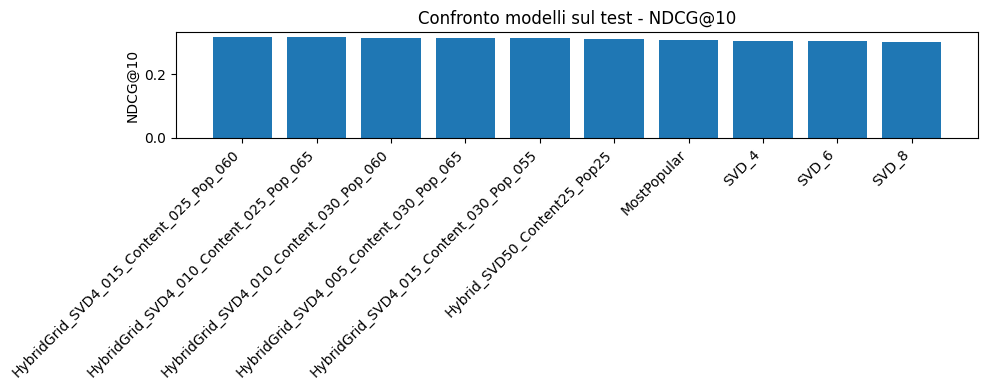

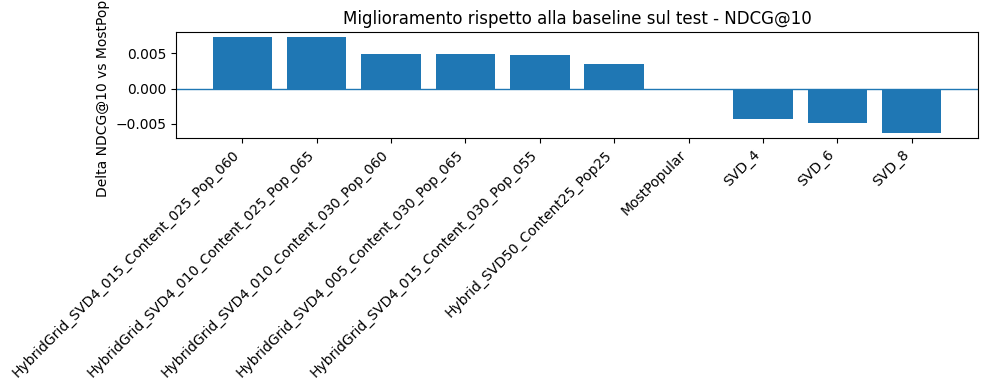

Grafici salvati in:
C:\Users\arsid\Desktop\Tesi-ecommerce\notebooks\test_dataset2\data\processed\test_dataset2_recommender\notebook05_content_hybrid\notebook05_test_ndcg_at_10.png
C:\Users\arsid\Desktop\Tesi-ecommerce\notebooks\test_dataset2\data\processed\test_dataset2_recommender\notebook05_content_hybrid\notebook05_test_delta_ndcg_at_10_vs_popularity.png


In [29]:
import matplotlib.pyplot as plt

plot_test_df=primary_test_comparison_df.head(10).copy()
delta_col=f"{PRIMARY_METRIC}_delta_vs_popularity"
metric_label=f"{PRIMARY_METRIC.upper()}@{PRIMARY_K}"
FIG_TEST_METRIC_PATH=NOTEBOOK05_DIR/f"notebook05_test_{PRIMARY_METRIC}_at_{PRIMARY_K}.png"
FIG_DELTA_PATH=NOTEBOOK05_DIR/f"notebook05_test_delta_{PRIMARY_METRIC}_at_{PRIMARY_K}_vs_popularity.png"

if plot_test_df.empty:
    print("Nessun risultato disponibile per generare i grafici finali")
else:
    plt.figure(figsize=(10,4))
    plt.bar(plot_test_df["model"],plot_test_df[PRIMARY_METRIC])
    plt.xticks(rotation=45,ha="right")
    plt.ylabel(metric_label)
    plt.title(f"Confronto modelli sul test - {metric_label}")
    plt.tight_layout()
    plt.savefig(FIG_TEST_METRIC_PATH,dpi=160,bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(10,4))
    plt.bar(plot_test_df["model"],plot_test_df[delta_col])
    plt.axhline(0,linewidth=1)
    plt.xticks(rotation=45,ha="right")
    plt.ylabel(f"Delta {metric_label} vs MostPopular")
    plt.title(f"Miglioramento rispetto alla baseline sul test - {metric_label}")
    plt.tight_layout()
    plt.savefig(FIG_DELTA_PATH,dpi=160,bbox_inches="tight")
    plt.show()

    print("Grafici salvati in:")
    print(FIG_TEST_METRIC_PATH)
    print(FIG_DELTA_PATH)

## 12 salvataggio output

In [26]:
#salviamo metriche, confronti, rank e testi dei prodotti,TFIDF, profili utente
NOTEBOOK05_METRICS_PATH=NOTEBOOK05_DIR/"notebook05_metrics.csv"
NOTEBOOK05_ALL_COMPARISON_PATH=NOTEBOOK05_DIR/"notebook05_all_models_comparison.csv"
NOTEBOOK05_VALIDATION_RANKS_PATH=NOTEBOOK05_DIR/"notebook05_validation_ranks.parquet"
NOTEBOOK05_TEST_RANKS_PATH=NOTEBOOK05_DIR/"notebook05_test_ranks.parquet"
NOTEBOOK05_SUMMARY_PATH=NOTEBOOK05_DIR/"notebook05_summary.json"
NOTEBOOK05_CATEGORY_METRICS_PATH=NOTEBOOK05_DIR/"notebook05_category_metrics.csv"
CONTENT_TEXT_PATH=NOTEBOOK05_DIR/"item_content_text.parquet"
TFIDF_VECTORIZER_PATH=NOTEBOOK05_DIR/"tfidf_vectorizer.joblib"
ITEM_TFIDF_MATRIX_PATH=NOTEBOOK05_DIR/"item_tfidf_matrix.npz"
USER_PROFILE_MATRIX_PATH=NOTEBOOK05_DIR/"user_content_profiles.npz"
POPULARITY_SCORES_OUT_PATH=NOTEBOOK05_DIR/"popularity_scores.parquet"
SVD_INFO_OUT_PATH=NOTEBOOK05_DIR/"svd_component_info.json"
HYBRID_GRID_VALIDATION_METRICS_PATH=NOTEBOOK05_DIR/"hybrid_grid_validation_metrics.csv"
HYBRID_GRID_TOP_WEIGHTS_PATH=NOTEBOOK05_DIR/"hybrid_grid_top_weights.csv"

In [27]:
notebook05_metrics_df.to_csv(NOTEBOOK05_METRICS_PATH,index=False)
comparison_sorted_df.to_csv(NOTEBOOK05_ALL_COMPARISON_PATH,index=False)
if not notebook05_category_metrics_df.empty:
    notebook05_category_metrics_df.to_csv(NOTEBOOK05_CATEGORY_METRICS_PATH,index=False)
items_text_df.to_parquet(CONTENT_TEXT_PATH,index=False)
popularity_scores_df.to_parquet(POPULARITY_SCORES_OUT_PATH,index=False)

if "hybrid_grid_validation_metrics_df" in globals() and not hybrid_grid_validation_metrics_df.empty:
    hybrid_grid_validation_metrics_df.to_csv(HYBRID_GRID_VALIDATION_METRICS_PATH,index=False)

if "best_hybrid_grid_weights_df" in globals() and not best_hybrid_grid_weights_df.empty:
    best_hybrid_grid_weights_df.to_csv(HYBRID_GRID_TOP_WEIGHTS_PATH,index=False)

if SAVE_RANKS:
    notebook05_validation_ranks_df.to_parquet(NOTEBOOK05_VALIDATION_RANKS_PATH,index=False)
    notebook05_test_ranks_df.to_parquet(NOTEBOOK05_TEST_RANKS_PATH,index=False)

if SAVE_CONTENT_ARTIFACTS:
    joblib.dump(tfidf_vectorizer,TFIDF_VECTORIZER_PATH)
    save_npz(ITEM_TFIDF_MATRIX_PATH,item_tfidf_matrix)
    save_npz(USER_PROFILE_MATRIX_PATH,user_profile_matrix)
    SVD_INFO_OUT_PATH.write_text(json.dumps(svd_info,indent=2,ensure_ascii=False),encoding="utf-8")
#dizionario riassuntivo notebook05
summary={
    "category":CATEGORY,
    "dataset_name":DATASET_NAME,
    "primary_metric":PRIMARY_METRIC,
    "primary_k":int(PRIMARY_K),
    "best_overall_model_validation":best_overall_model_name,
    "best_overall_validation_score":best_overall_validation_score,
    "best_notebook05_model_validation":best_notebook05_model_name,
    "best_notebook05_validation_score":best_notebook05_validation_score,
    "models_notebook05":list(notebook05_score_functions.keys()),
    "run_hybrid_grid_search":bool(RUN_HYBRID_GRID_SEARCH),
    "hybrid_grid_step":float(HYBRID_GRID_STEP),
    "hybrid_grid_include_zero":bool(HYBRID_GRID_INCLUDE_ZERO),
    "hybrid_grid_combinations":int(len(hybrid_weight_grid_df)) if "hybrid_weight_grid_df" in globals() else 0,
    "hybrid_grid_top_models_kept":int(HYBRID_GRID_TOP_MODELS_TO_KEEP),
    "hybrid_grid_validation_metrics_path":str(HYBRID_GRID_VALIDATION_METRICS_PATH) if "hybrid_grid_validation_metrics_df" in globals() and not hybrid_grid_validation_metrics_df.empty else None,
    "hybrid_grid_top_weights_path":str(HYBRID_GRID_TOP_WEIGHTS_PATH) if "best_hybrid_grid_weights_df" in globals() and not best_hybrid_grid_weights_df.empty else None,
    "tfidf_features":int(item_tfidf_matrix.shape[1]),
    "tfidf_non_zero_values":int(item_tfidf_matrix.nnz),
    "user_profile_non_zero_values":int(user_profile_matrix.nnz),
    "svd_available":bool(svd_available),
    "svd_info":svd_info,
    "train_rows":int(len(train_df)),
    "validation_samples":int(len(validation_samples_df)),
    "test_samples":int(len(test_samples_df)),
    "n_users":int(n_users),
    "n_items":int(n_items),
    "metrics_path":str(NOTEBOOK05_METRICS_PATH),
    "comparison_path":str(NOTEBOOK05_ALL_COMPARISON_PATH),
    "category_metrics_path":str(NOTEBOOK05_CATEGORY_METRICS_PATH) if not notebook05_category_metrics_df.empty else None,
    "content_text_path":str(CONTENT_TEXT_PATH),
    "tfidf_vectorizer_path":str(TFIDF_VECTORIZER_PATH) if SAVE_CONTENT_ARTIFACTS else None,
    "item_tfidf_matrix_path":str(ITEM_TFIDF_MATRIX_PATH) if SAVE_CONTENT_ARTIFACTS else None,
    "user_profile_matrix_path":str(USER_PROFILE_MATRIX_PATH) if SAVE_CONTENT_ARTIFACTS else None,
}

NOTEBOOK05_SUMMARY_PATH.write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding="utf-8")

display(pd.DataFrame.from_dict(summary,orient="index",columns=["value"]))

,value
category,AmazonLike_v1
dataset_name,test_dataset2
primary_metric,ndcg
primary_k,10
best_overall_model_validation,HybridGrid_SVD4_010_Content_025_Pop_065
best_overall_validation_score,0.311657
best_notebook05_model_validation,HybridGrid_SVD4_010_Content_025_Pop_065
best_notebook05_validation_score,0.311657
models_notebook05,"[ContentTFIDF, Hybrid_Content70_Pop30, Hybrid_SVD70_Content30, Hybrid_SVD50_Content25_Pop25, Hybrid_SVD40_Content40_Pop20, HybridGrid_SVD4_010_Content_025_P..."
run_hybrid_grid_search,True
